# Recalibración conforme adaptativa del VaR

**Pregunta:** Cuando un modelo de VaR se queda atrás en una crisis, ¿puede un envoltorio que mueve el nivel de cola del modelo después de
cada excepción devolver la cobertura que piden los backtests, en las ventanas de estrés del caso C11 y en un generador cuyo VaR
verdadero se conoce, sin empeorar el puntaje FZ0 del modelo?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 02, 03 y 05 de este tema (la escalera de estimadores, los backtests y la evaluación
  consistente)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- escribir la actualización de nivel de la inferencia conforme adaptativa y decir qué le hacen al nivel de trabajo una excepción y un
  día sin excepción;
- leer lo que promete la garantía de largo plazo de Gibbs y Candes sobre una ventana de unos cientos de días, y lo que no promete;
- repetir una corrida envuelta versionada desde sus excepciones, y medir en un generador de VaR conocido cuán lejos del objetivo
  está la probabilidad verdadera de excepción de cada pronóstico, antes y después del envoltorio;
- probar la afirmación del caso en las tres ventanas de estrés desde las excepciones versionadas, y decir dónde el envoltorio cuesta
  cobertura.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca
instala nada por sí mismo. La celda siguiente importa lo que usa el notebook e imprime las versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.market import conformal as cf
from riskvalidation.market import garch
from riskvalidation.validation import market as vm
from scipy import stats

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C11 somete a backtest una escalera de modelos de VaR y ES en seis ventanas de retornos reales: una posición larga en renta
variable de EE. UU. (el factor de mercado de Fama y French, de la biblioteca de datos de Kenneth French), un bono par del Tesoro de
EE. UU. a 10 años (la curva par diaria del Tesoro), el euro contra el dólar (la publicación H.10 de la Reserva Federal) y una cartera
mixta. El pronóstico del día $t$ usa solo los retornos hasta $t-1$. La serie de renta variable es solo derivada: sus pérdidas
realizadas no se publican en los documentos versionados, mientras que los pronósticos de cada modelo, sus días de excepción y sus
puntajes sí. Tres de las ventanas son las ventanas de estrés de la afirmación: renta variable 2007 a 2009, renta variable 2020 y tasas
2022. Cada documento trae además las corridas envueltas de HS-250, GARCH-t y FHS al 1 % y al 2,5 %.

In [2]:
# Leer los documentos versionados del caso C11: las seis ventanas, las excepciones de cada modelo y lo envuelto
C11 = ROOT / "data" / "derived" / "C11"
WINDOWS = ("equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "calm-2004-06", "mixed-2023")
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8"))["outputs"] for w in WINDOWS}
run = docs["equity-2007-09"]["conformal"]["hypothesis"]["run"]
GAMMA, LOW, HIGH = run["gamma"], run["level_min"], run["level_max"]
print(f"gamma {GAMMA} | banda [{LOW}, {HIGH}] | ventanas de estrés: {', '.join(run['stress_windows'])}")
for w, o in docs.items():
    status = o["grid"]["realised_loss"]["status"]
    rows = len(o["conformal"]["rows"])
    print(f"{w:15s} {len(o['grid']['dates']):4d} días | pérdida realizada: {status} | {rows} corridas envueltas")


gamma 0.005 | banda [0.001, 0.25] | ventanas de estrés: equity-2007-09, equity-2020, rates-2022
equity-2007-09   504 días | pérdida realizada: withheld-derived-only | 6 corridas envueltas
equity-2020      104 días | pérdida realizada: withheld-derived-only | 6 corridas envueltas
rates-2022       249 días | pérdida realizada: included | 6 corridas envueltas
fx-2008          251 días | pérdida realizada: included | 6 corridas envueltas
calm-2004-06     750 días | pérdida realizada: withheld-derived-only | 6 corridas envueltas
mixed-2023        64 días | pérdida realizada: withheld-derived-only | 6 corridas envueltas


## Método

Un modelo de VaR da, para el día $t$ y un nivel de cola $a$, un pronóstico $\mathrm{VaR}_t(a)$ construido con los retornos anteriores
a $t$. El envoltorio no toca el modelo. Mantiene un nivel de trabajo $a_t$, que parte en el objetivo $\alpha$, le pide al modelo su VaR
en $a_t$ y, después del día, mueve el nivel (Gibbs y Candes, 2021):

$$a_{t+1} = \operatorname{clip}\big(a_t + \gamma\,(\alpha - \mathrm{err}_t),\ a_{\min},\ a_{\max}\big), \qquad
\mathrm{err}_t = \mathbb{1}\{y_t < \mathrm{VaR}_t(a_t)\}.$$

Una excepción baja el nivel en $\gamma(1-\alpha)$, de modo que el VaR siguiente es más profundo; un día sin excepción lo sube en
$\gamma\alpha$. El paso $\gamma = 0{,}005$ y la banda $[0{,}001;\ 0{,}25]$ se fijaron antes de toda corrida. El módulo
`market.conformal` del motor contiene la actualización, el envoltorio y la comparación; la celda siguiente recorre la actualización a
mano.

In [3]:
# La actualización del nivel paso a paso: un objetivo de 1 %, diez días sin excepción, una excepción y otros diez días
level = 0.01
path = [level]
for hit in [False] * 10 + [True] + [False] * 10:
    level = cf.aci_update(level, hit, 0.01, GAMMA, LOW, HIGH)
    path.append(level)
print(" ".join(f"{100 * x:.3f}" for x in path))
print(f"un día sin excepción sube el nivel en {100 * GAMMA * 0.01:.4f} pp")
print(f"una excepción lo baja en {100 * GAMMA * 0.99:.3f} pp")
print(f"días sin excepción para deshacer una: {0.99 / 0.01:.0f}")
# La cota de Gibbs y Candes sobre la brecha entre la tasa de excepciones y el objetivo, para una corrida de T días
for days in (250, 504, 2500, 39800):
    print(f"T {days:6d} | brecha máxima entre la tasa de excepciones y 1 %: {(0.99 + GAMMA) / (GAMMA * days):.4f}")


1.000 1.005 1.010 1.015 1.020 1.025 1.030 1.035 1.040 1.045 1.050 0.555 0.560 0.565 0.570 0.575 0.580 0.585 0.590 0.595 0.600 0.605
un día sin excepción sube el nivel en 0.0050 pp
una excepción lo baja en 0.495 pp
días sin excepción para deshacer una: 99
T    250 | brecha máxima entre la tasa de excepciones y 1 %: 0.7960
T    504 | brecha máxima entre la tasa de excepciones y 1 %: 0.3948
T   2500 | brecha máxima entre la tasa de excepciones y 1 %: 0.0796
T  39800 | brecha máxima entre la tasa de excepciones y 1 %: 0.0050


Al 1 % un día sin excepción suma 0,005 puntos porcentuales al nivel y una excepción le quita 0,495, así que deshacer una excepción
toma 99 días sin excepción: el nivel reacciona de inmediato a un grupo de excepciones y se relaja lento. La garantía es de largo plazo.
Gibbs y Candes acotan la brecha entre la tasa de excepciones y el objetivo por $(\max(a_1, 1-a_1) + \gamma)/(\gamma T)$, que con
$\gamma = 0{,}005$ vale 0,796 en 250 días y 0,395 en los 504 días de la renta variable 2007 a 2009: admite cualquier tasa de excepciones
entre 0 y 40 %. La cota llega a medio punto porcentual solo después de 39.800 días, unos 158 años de mercado. Sobre una ventana de
estrés el teorema no dice nada, así que lo que el envoltorio hace allí hay que medirlo.

In [4]:
# Repetir el nivel de trabajo de GARCH-t al 1 % en equity-2007-09 desde las excepciones de su VaR envuelto versionado
eq = docs["equity-2007-09"]
row = next(r for r in eq["conformal"]["rows"] if r["model_id"] == "garch-t" and r["alpha"] == 0.01)
n = row["n_days"]
wrapped_hits = np.zeros(n, bool)
wrapped_hits[row["series"]["exceedance_days"]] = True
levels = [0.01]
for hit in wrapped_hits[:-1]:
    levels.append(cf.aci_update(levels[-1], bool(hit), 0.01, GAMMA, LOW, HIGH))
levels = np.array(levels)
gap = np.abs(levels - np.array(row["series"]["working_level"])).max()
print(f"brecha máxima entre el nivel repetido y el versionado: {gap:.1e}")
print(f"min {100 * levels.min():.3f} % | media {100 * levels.mean():.3f} % | max {100 * levels.max():.3f} %")
print(f"días en el piso de la banda: {int((levels <= LOW + 1e-12).sum())} | días recortados: {row['n_clipped']}")


brecha máxima entre el nivel repetido y el versionado: 4.7e-17
min 0.100 % | media 0.515 % | max 1.075 %
días en el piso de la banda: 3 | días recortados: 3


La actualización aplicada a las 6 excepciones versionadas del GARCH-t envuelto reproduce el nivel de trabajo versionado con
precisión de máquina (la brecha máxima es 4,7e-17). El nivel cayó del 1 % al piso de la banda, 0,1 %, y lo tocó en 3 días, los 3 días
que el documento informa como recortados; su media en la ventana es 0,515 % y su valor más alto 1,075 %. La figura pone el nivel junto
a las excepciones.

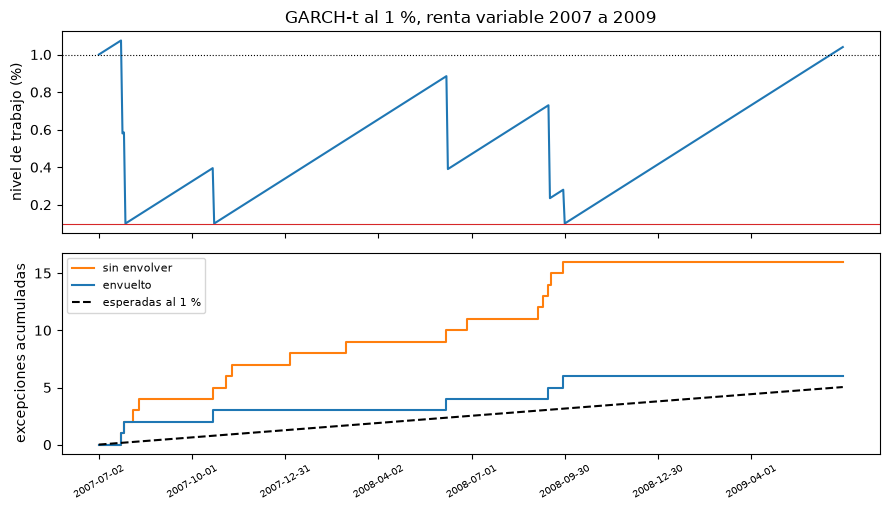

sin envolver: 16 | envuelto: 6 | esperadas al 1 %: 5.04


In [5]:
# Dibujar el nivel de trabajo y las excepciones acumuladas de GARCH-t al 1 % en equity-2007-09, sin envolver y envuelto
ladder = {m["model_id"]: m for m in eq["models"]}
plain = next(b for b in ladder["garch-t"]["by_level"] if b["alpha"] == 0.01)
plain_hits = np.zeros(n, bool)
plain_hits[plain["exceedance_days"]] = True
dates = eq["grid"]["dates"]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
top.plot(100 * levels, color="tab:blue")
top.axhline(1.0, color="black", linestyle=":", linewidth=0.8)
top.axhline(100 * LOW, color="tab:red", linewidth=0.8)
top.set_ylabel("nivel de trabajo (%)")
top.set_title("GARCH-t al 1 %, renta variable 2007 a 2009")
bottom.step(range(n), np.cumsum(plain_hits), where="post", color="tab:orange", label="sin envolver")
bottom.step(range(n), np.cumsum(wrapped_hits), where="post", color="tab:blue", label="envuelto")
bottom.plot(0.01 * np.arange(1, n + 1), color="black", linestyle="--", label="esperadas al 1 %")
bottom.set_ylabel("excepciones acumuladas")
ticks = list(range(0, n, 63))
bottom.set_xticks(ticks)
bottom.set_xticklabels([dates[i] for i in ticks], rotation=30, fontsize=7)
bottom.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"sin envolver: {int(plain_hits.sum())} | envuelto: {int(wrapped_hits.sum())} | "
      f"esperadas al 1 %: {0.01 * n:.2f}")


El panel superior es el nivel de trabajo: cae al piso con las excepciones de fines de julio de 2007, de octubre de 2007 y de fines
de septiembre de 2008, cae a la mitad con la excepción de junio de 2008, y entre ellas sube 0,005 puntos por día; después de la última
excepción necesita hasta junio de 2009 para volver al 1 %. El panel inferior cuenta las excepciones. El modelo con nivel fijo de 1 %
(naranja) tiene 16 excepciones en 504 días frente a 5,04 esperadas, agrupadas, con los grupos mayores en el verano de 2007 y en
septiembre de 2008; envuelto (azul) tiene 6, cerca de la línea discontinua del objetivo todo el tiempo. El modelo envuelto le pide a
GARCH-t un cuantil más profundo mientras dura la crisis, y eso es todo el método.

## Comparación

Los métodos comparados son cada modelo tal como lo corre la escalera, con nivel fijo, y el mismo modelo envuelto. Una ventana real
tiene una sola trayectoria y ningún VaR conocido, así que un conteo de 6 excepciones frente a 16 no puede decir cuán lejos de la verdad
estuvo cada pronóstico. Por eso la comparación corre el generador del estudio del motor, donde el VaR verdadero de cada día se conoce:
un GARCH(1,1) con innovaciones t de Student de 5 grados después de una historia tranquila de 1.000 días, y luego 500 días cuya
volatilidad sube al triple, se mantiene y cae a 1,5 veces, la forma de 2007 a 2009. HS-250 desplaza su ventana de 250 días; GARCH-t
se ajusta una vez sobre la historia tranquila y se filtra día a día. La probabilidad verdadera de excepción de un pronóstico es la
función de distribución t de Student en el pronóstico escalado por la volatilidad verdadera, así que la cobertura de cada día se mide
sin ruido de muestreo.

In [6]:
# El generador del estudio del motor: una historia tranquila GARCH(1,1)-t de 1.000 días y luego 500 días cuya
# volatilidad sube al triple en 250 días, se mantiene 100 y cae a 1,5 veces; el VaR verdadero de cada día se conoce
NU, HISTORY, LENGTH = 5.0, 1000, 500
SCALE = np.sqrt((NU - 2) / NU)


def crisis_path(rng):
    z = rng.standard_t(NU, HISTORY + LENGTH + 300) * SCALE
    ramp = np.interp(np.arange(LENGTH), [0, 250, 350, LENGTH - 1], [1.0, 3.0, 3.0, 1.5])
    mult = np.concatenate([np.ones(300 + HISTORY), ramp])
    s2, y, sd = 2e-6 / 0.02, np.empty(z.size), np.empty(z.size)
    for t in range(z.size):
        e = np.sqrt(s2) * z[t]
        y[t] = mult[t] * e
        sd[t] = mult[t] * np.sqrt(s2)
        s2 = 2e-6 + 0.08 * e * e + 0.90 * s2
    return y[300:], sd[300:]


# La probabilidad verdadera de que el retorno del día caiga bajo un VaR pronosticado
def true_level(var, sd):
    return stats.t.cdf(var / (sd * SCALE), NU)


# GARCH(1,1)-t ajustado una vez sobre la historia tranquila y luego filtrado día a día
def frozen_garch(y):
    fit = garch.fit_garch(y[:HISTORY], "garch", "student-t", "constant")
    return lambda t, level: garch.garch_var_es_forecast(fit, y[max(0, t - HISTORY):t], level)


La celda siguiente dibuja una trayectoria del generador, semilla 20261030, y corre ambos modelos dos veces sobre su ventana de 500
días: con nivel fijo de 1 % y envueltos. Cada corrida se evalúa por sus excepciones, con la prueba de Kupiec como la leería una mesa, y
por la probabilidad verdadera de excepción de cada pronóstico, un número que solo un generador de VaR conocido puede dar.

In [7]:
# Una trayectoria: HS-250 y GARCH-t, sin envolver y envueltos al 1 %, evaluados por sus excepciones y el nivel verdadero
y, sd = crisis_path(np.random.default_rng(20261030))
models = {"HS-250": cf.historical_forecaster(y, 250), "GARCH-t": frozen_garch(y)}
runs = {}
for name, f in models.items():
    c = cf.aci_compare(y, f, 0.01, gamma=GAMMA, start=HISTORY)
    plain_run = cf.aci_var_es(y, f, 0.01, 0.0, HISTORY)
    runs[name] = (plain_run, c.result)
    for side, s, r in (("sin envolver", c.unwrapped, plain_run), ("envuelto", c.wrapped, c.result)):
        p = true_level(r.var, sd[HISTORY:]).mean()
        print(f"{name:8s} {side:12s} excepciones {s.n_hits:3d} / {s.n} | Kupiec {s.kupiec_p:.3f} | "
              f"probabilidad verdadera {100 * p:.2f} %")
    print(f"{name:8s} cambio de FZ0 {100 * c.fz0_change:+.1f} % | días recortados {c.result.n_clipped}")


HS-250   sin envolver excepciones  16 / 500 | Kupiec 0.000 | probabilidad verdadera 3.66 %
HS-250   envuelto     excepciones  10 / 500 | Kupiec 0.048 | probabilidad verdadera 2.27 %
HS-250   cambio de FZ0 -6.4 % | días recortados 7
GARCH-t  sin envolver excepciones   7 / 500 | Kupiec 0.397 | probabilidad verdadera 1.30 %
GARCH-t  envuelto     excepciones   6 / 500 | Kupiec 0.663 | probabilidad verdadera 1.10 %
GARCH-t  cambio de FZ0 +3.0 % | días recortados 0


En esta trayectoria HS-250 con nivel fijo de 1 % tiene 16 excepciones en 500 días y falla Kupiec (p 0,000); su probabilidad
verdadera de excepción promedia 3,66 %, más del triple del objetivo. Envuelto tiene 10 excepciones, p de Kupiec 0,048 y una
probabilidad verdadera de 2,27 %: mejor, todavía sobre el objetivo, y el nivel llegó al piso en 7 días. GARCH-t sigue la volatilidad
por construcción y ya está cerca: 7 excepciones y 1,30 % sin envolver, 6 excepciones y 1,10 % envuelto, a un costo de 3,0 % en FZ0.
La figura muestra HS-250.

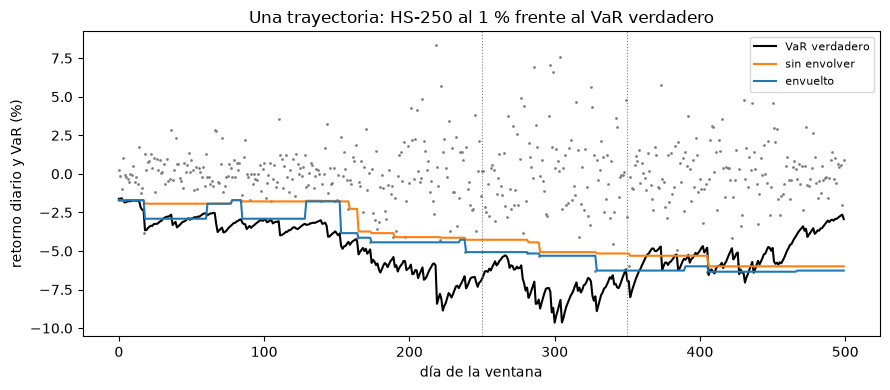

In [8]:
# Dibujar la ventana de esa trayectoria: los retornos, el VaR verdadero al 1 % y el de HS-250 sin envolver y envuelto
days = np.arange(LENGTH)
truth = sd[HISTORY:] * SCALE * stats.t.ppf(0.01, NU)
plain_run, wrapped_run = runs["HS-250"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, 100 * y[HISTORY:], ".", color="grey", markersize=2)
ax.plot(days, 100 * truth, color="black", label="VaR verdadero")
ax.plot(days, 100 * plain_run.var, color="tab:orange", label="sin envolver")
ax.plot(days, 100 * wrapped_run.var, color="tab:blue", label="envuelto")
for edge in (250, 350):
    ax.axvline(edge, color="grey", linestyle=":", linewidth=0.8)
ax.set_xlabel("día de la ventana")
ax.set_ylabel("retorno diario y VaR (%)")
ax.set_title("Una trayectoria: HS-250 al 1 % frente al VaR verdadero")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


La línea negra es el VaR verdadero al 1 %; baja con la volatilidad en la subida (hasta el día 250), se mantiene en la meseta y
sube en la caída. El VaR naranja de HS-250 la sigue con meses de atraso, porque su ventana de 250 días conserva los días tranquilos
hasta que salen de ella. El VaR azul envuelto baja del naranja después de las primeras excepciones, cerca del día 20, y queda más cerca
de la verdad en la meseta. Desde el día 400, aproximadamente, ambos están más abajo que la verdad: HS-250 porque su ventana todavía
contiene la crisis, el VaR envuelto también porque su nivel se recupera solo 0,005 puntos por día.

In [9]:
# Treinta trayectorias del mismo generador: la probabilidad verdadera de excepción de cada pronóstico, por fase
PHASES = ((0, 250), (250, 350), (350, 500))
study = {"HS-250": [], "GARCH-t": []}
for rep in range(30):
    y_r, sd_r = crisis_path(np.random.default_rng([20261030, rep]))
    for name, f in (("HS-250", cf.historical_forecaster(y_r, 250)), ("GARCH-t", frozen_garch(y_r))):
        pair = [cf.aci_var_es(y_r, f, 0.01, g, HISTORY) for g in (0.0, GAMMA)]
        scores = [cf.forecast_scores(y_r[HISTORY:], r.var, r.es, 0.01) for r in pair]
        probs = [true_level(r.var, sd_r[HISTORY:]) for r in pair]
        passed = [s.kupiec_p is not None and s.cc_p is not None and min(s.kupiec_p, s.cc_p) >= 0.05 for s in scores]
        change = (scores[1].fz0_mean - scores[0].fz0_mean) / abs(scores[0].fz0_mean)
        phases = [p[a:b].mean() for p in probs for a, b in PHASES]
        study[name].append([p.mean() for p in probs] + passed + [change] + phases)
for name, rows in study.items():
    x = np.array(rows, float)
    by_phase = zip(x[:, 5:8].mean(0), x[:, 8:11].mean(0))
    print(f"{name:8s} probabilidad verdadera {100 * x[:, 0].mean():.2f} % / {100 * x[:, 1].mean():.2f} % | "
          f"tasa de aprobación {x[:, 2].mean():.2f} / {x[:, 3].mean():.2f} | "
          f"cambio de FZ0 {100 * np.median(x[:, 4]):+.1f} %")
    print(f"{'':8s} por fase: " + " | ".join(f"{100 * u:.2f} / {100 * w:.2f}" for u, w in by_phase))


HS-250   probabilidad verdadera 2.40 % / 1.37 % | tasa de aprobación 0.23 / 0.83 | cambio de FZ0 -8.5 %
         por fase: 3.43 / 1.90 | 2.25 / 1.25 | 0.79 / 0.57
GARCH-t  probabilidad verdadera 1.73 % / 1.15 % | tasa de aprobación 0.60 / 0.97 | cambio de FZ0 -0.2 %
         por fase: 1.78 / 1.33 | 1.90 / 1.13 | 1.55 / 0.88


En treinta trayectorias la probabilidad verdadera de excepción de HS-250 baja de 2,40 % a 1,37 % y su tasa de aprobación (Kupiec
y cobertura condicional, ambas con p de al menos 0,05) sube de 0,23 a 0,83, con un cambio mediano de FZ0 de -8,5 % (una mejora).
GARCH-t pasa de 1,73 % a 1,15 % y de 0,60 a 0,97, con un cambio mediano de FZ0 de -0,2 %. El estudio del motor, con 100 trayectorias,
midió tasas de aprobación de 0,18 a 0,87 y de 0,44 a 0,97 en el mismo escenario. La figura separa la ventana por fase.

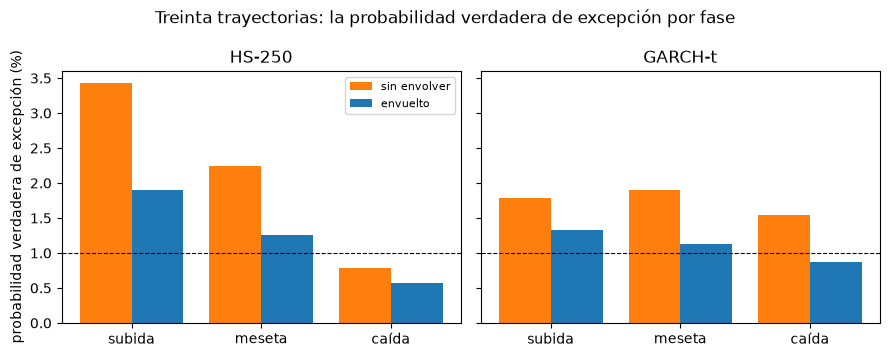

In [10]:
# Dibujar la probabilidad verdadera media de excepción por fase, ambos modelos sin envolver y envueltos, frente al 1 %
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
x = np.arange(3)
for ax, (name, rows) in zip(axes, study.items()):
    arr = np.array(rows, float)
    ax.bar(x - 0.2, 100 * arr[:, 5:8].mean(0), 0.4, color="tab:orange", label="sin envolver")
    ax.bar(x + 0.2, 100 * arr[:, 8:11].mean(0), 0.4, color="tab:blue", label="envuelto")
    ax.axhline(1.0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(["subida", "meseta", "caída"])
    ax.set_title(name)
axes[0].set_ylabel("probabilidad verdadera de excepción (%)")
axes[0].legend(fontsize=8)
fig.suptitle("Treinta trayectorias: la probabilidad verdadera de excepción por fase")
fig.tight_layout()
plt.show()


La línea discontinua es el objetivo de 1 %. En la subida HS-250 sin envolver está en 3,43 % y envuelto en 1,90 %; en la meseta en
2,25 % y 1,25 %. En la caída ambos quedan bajo el objetivo, 0,79 % y 0,57 %: el envoltorio mantiene un nivel de crisis durante meses
después de la crisis, y allí vuelve más conservador a un modelo que ya lo era. GARCH-t, que sigue la volatilidad, pasa de 1,78 %,
1,90 % y 1,55 % a 1,33 %, 1,13 % y 0,88 %. El envoltorio corrige el nivel que el modelo yerra en promedio; no distingue las fases.

## Evidencia

La afirmación, fijada en el SDD antes de toda corrida: HS-250, GARCH-t y FHS, envueltos, aprueban las pruebas de cobertura (Kupiec y
cobertura condicional, ambas con p de al menos 0,05) en al menos una ventana de estrés más, de las tres, que sin envolver, sin que su FZ0
medio empeore más de 5 %; queda refutada si el modelo envuelto falla la prueba de independencia en la renta variable 2007 a 2009. La
celda siguiente recalcula las tres pruebas de las 18 corridas de estrés, sin envolver y envueltas, desde los días de excepción
versionados, con `validation.market` del motor.

In [11]:
# Recalcular las pruebas de cobertura de cada corrida de estrés desde sus días de excepción versionados
def passes(days, n_days, alpha):
    flags = np.zeros(n_days, bool)
    flags[days] = True
    kupiec = vm.kupiec_pof(flags, alpha).p_value
    cc = vm.christoffersen_conditional_coverage(flags, alpha).p_value
    indep = vm.christoffersen_independence(flags, alpha).p_value
    return kupiec is not None and cc is not None and min(kupiec, cc) >= 0.05, indep


cells = {}
for w in run["stress_windows"]:
    ladder_w = {m["model_id"]: m for m in docs[w]["models"]}
    for r in docs[w]["conformal"]["rows"]:
        plain_w = next(b for b in ladder_w[r["model_id"]]["by_level"] if b["alpha"] == r["alpha"])
        before, _ = passes(plain_w["exceedance_days"], r["n_days"], r["alpha"])
        after, indep = passes(r["series"]["exceedance_days"], r["n_days"], r["alpha"])
        cell = cells.setdefault((r["model_id"], r["alpha"]), {"before": 0, "after": 0, "fz0": [], "indep": None})
        cell["before"] += before
        cell["after"] += after
        cell["fz0"].append(r["fz0_change"])
        if w == "equity-2007-09":
            cell["indep"] = indep
for (model, alpha), c in cells.items():
    print(f"{model:8s} {100 * alpha:.1f} % | ventanas de estrés aprobadas {c['before']} / {c['after']} | "
          f"peor cambio de FZ0 {100 * max(c['fz0']):+.1f} % | p de independencia envuelto en 2007-09 {c['indep']:.3f}")


hs-250   1.0 % | ventanas de estrés aprobadas 0 / 1 | peor cambio de FZ0 -5.8 % | p de independencia envuelto en 2007-09 0.483
hs-250   2.5 % | ventanas de estrés aprobadas 0 / 2 | peor cambio de FZ0 -3.3 % | p de independencia envuelto en 2007-09 0.275
garch-t  1.0 % | ventanas de estrés aprobadas 2 / 3 | peor cambio de FZ0 +3.0 % | p de independencia envuelto en 2007-09 0.703
garch-t  2.5 % | ventanas de estrés aprobadas 1 / 3 | peor cambio de FZ0 -0.3 % | p de independencia envuelto en 2007-09 0.371
fhs      1.0 % | ventanas de estrés aprobadas 2 / 3 | peor cambio de FZ0 +3.4 % | p de independencia envuelto en 2007-09 0.657
fhs      2.5 % | ventanas de estrés aprobadas 1 / 3 | peor cambio de FZ0 +1.5 % | p de independencia envuelto en 2007-09 0.371


Sin envolver, las seis celdas de modelo y nivel aprueban 6 de sus 18 corridas de estrés; envueltas, 15. HS-250 gana una ventana al
1 % y dos al 2,5 %, GARCH-t una y dos, FHS una y dos. El peor cambio de FZ0 es +3,4 % (FHS al 1 % en la renta variable 2020), dentro
del 5 % permitido. Los valores p de independencia envueltos en la renta variable 2007 a 2009 van de 0,275 a 0,703, así que la condición
de refutación no ocurre. Los cambios de FZ0 de las ventanas de renta variable se leen de los documentos, porque sus pérdidas no se
publican; tasas 2022 sí versiona sus pérdidas, y la celda siguiente recalcula allí el cambio de FZ0 desde los pronósticos
versionados.

In [12]:
# Recalcular el cambio de FZ0 donde la pérdida realizada está versionada (rates-2022), desde los pronósticos versionados
rates = docs["rates-2022"]
loss = np.array(rates["grid"]["realised_loss"]["loss"], float)
ladder_r = {m["model_id"]: m for m in rates["models"]}
for r in rates["conformal"]["rows"]:
    plain_r = next(b for b in ladder_r[r["model_id"]]["by_level"] if b["alpha"] == r["alpha"])
    before = cf.forecast_scores(-loss, -np.array(plain_r["var"]), -np.array(plain_r["es"]), r["alpha"])
    after = cf.forecast_scores(-loss, -np.array(r["series"]["var"]), -np.array(r["series"]["es"]), r["alpha"])
    change = (after.fz0_mean - before.fz0_mean) / abs(before.fz0_mean)
    print(f"{r['model_id']:8s} {100 * r['alpha']:.1f} % | excepciones {before.n_hits} / {after.n_hits} | "
          f"FZ0 {before.fz0_mean:.3f} / {after.fz0_mean:.3f} | cambio de FZ0 {100 * change:+.1f} %")


hs-250   1.0 % | excepciones 8 / 4 | FZ0 -3.462 / -3.664 | cambio de FZ0 -5.8 %
hs-250   2.5 % | excepciones 14 / 8 | FZ0 -3.794 / -3.919 | cambio de FZ0 -3.3 %
garch-t  1.0 % | excepciones 6 / 4 | FZ0 -3.664 / -3.671 | cambio de FZ0 -0.2 %
garch-t  2.5 % | excepciones 14 / 8 | FZ0 -3.906 / -3.920 | cambio de FZ0 -0.3 %
fhs      1.0 % | excepciones 5 / 5 | FZ0 -3.692 / -3.659 | cambio de FZ0 +0.9 %
fhs      2.5 % | excepciones 12 / 7 | FZ0 -3.932 / -3.942 | cambio de FZ0 -0.3 %


En tasas 2022 el envoltorio reduce a la mitad las excepciones de HS-250 (de 8 a 4 al 1 %, de 14 a 8 al 2,5 %) y mejora su FZ0 en
5,8 % y 3,3 %; GARCH-t y FHS cambian menos de 1 %, y FHS al 1 %, que ya aprobaba, mantiene sus 5 excepciones y pierde 0,9 % de FZ0. Los
cambios recalculados son los de los documentos. La figura reúne la afirmación.

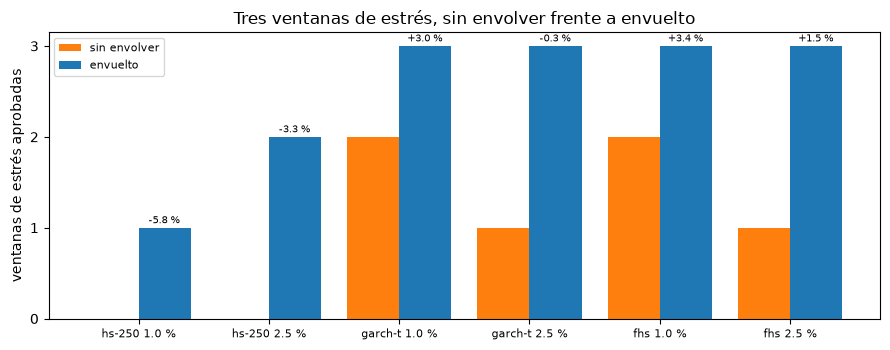

celdas donde la afirmación se cumple: 6 / 6 | aprobaciones de ventana ganadas: 9
La hipótesis se cumple en 6 de 6 celdas (modelo por nivel de cola): los modelos envueltos ganan 9 aprobaciones de ventanas de estrés en total, el peor cambio de FZ0 en una ventana de estrés es 3,4 %, y el envoltorio no falla la prueba de independencia en equity-2007-09. Se cumple en conjunto.


In [13]:
# Dibujar las ventanas de estrés que aprueba cada modelo en cada nivel de cola, sin envolver y envuelto, y el peor FZ0
labels = [f"{m} {100 * a:.1f} %" for m, a in cells]
x = np.arange(len(cells))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, [c["before"] for c in cells.values()], 0.4, color="tab:orange", label="sin envolver")
ax.bar(x + 0.2, [c["after"] for c in cells.values()], 0.4, color="tab:blue", label="envuelto")
for i, c in enumerate(cells.values()):
    ax.annotate(f"{100 * max(c['fz0']):+.1f} %", (i + 0.2, c["after"] + 0.05), ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_yticks(range(4))
ax.set_ylabel("ventanas de estrés aprobadas")
ax.set_title("Tres ventanas de estrés, sin envolver frente a envuelto")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
held = sum(c["after"] > c["before"] and max(c["fz0"]) <= run["fz0_tolerance"] for c in cells.values())
gained = sum(c["after"] - c["before"] for c in cells.values())
print(f"celdas donde la afirmación se cumple: {held} / {len(cells)} | aprobaciones de ventana ganadas: {gained}")
print(docs["equity-2007-09"]["conformal"]["hypothesis"]["verdict"]["es"])


Cada par de barras es un modelo en un nivel de cola: la naranja cuenta las ventanas de estrés que aprueba tal como lo corre la
escalera, la azul las que aprueba envuelto, y la etiqueta es el peor cambio de FZ0 en las tres. Toda barra azul es más alta y toda
etiqueta queda bajo +5 %, así que la afirmación se cumple en 6 de 6 celdas y los modelos envueltos ganan 9 aprobaciones de ventana,
como dice el veredicto versionado del caso. HS-250 envuelto todavía falla la renta variable 2020 en ambos niveles: el envoltorio
estrecha una caída que no ve venir, no la elimina. Queda una pregunta: cuánto le debe el resultado al paso.

In [14]:
# El paso se fijó en 0,005 antes de toda corrida; cuánto depende de él, en la primera trayectoria, HS-250 al 1 %
hs = cf.historical_forecaster(y, 250)
for g in (0.001, 0.002, 0.005, 0.01, 0.02):
    c = cf.aci_compare(y, hs, 0.01, gamma=g, start=HISTORY)
    p = true_level(c.result.var, sd[HISTORY:])
    by_phase = " / ".join(f"{100 * p[a:b].mean():.2f}" for a, b in PHASES)
    print(f"gamma {g:.3f} | excepciones {c.wrapped.n_hits:3d} | probabilidad verdadera {100 * p.mean():.2f} % | "
          f"por fase {by_phase} | cambio de FZ0 {100 * c.fz0_change:+.1f} %")


gamma 0.001 | excepciones  13 | probabilidad verdadera 3.08 % | por fase 4.70 / 2.79 / 0.57 | cambio de FZ0 -8.5 %
gamma 0.002 | excepciones  11 | probabilidad verdadera 2.83 % | por fase 4.20 / 2.79 / 0.57 | cambio de FZ0 -8.9 %
gamma 0.005 | excepciones  10 | probabilidad verdadera 2.27 % | por fase 3.07 / 2.79 / 0.58 | cambio de FZ0 -6.4 %
gamma 0.010 | excepciones  11 | probabilidad verdadera 2.08 % | por fase 2.60 / 2.95 / 0.62 | cambio de FZ0 -3.0 %
gamma 0.020 | excepciones  12 | probabilidad verdadera 2.32 % | por fase 2.95 / 3.21 / 0.69 | cambio de FZ0 -7.6 %


En esta trayectoria ningún paso lleva HS-250 al objetivo. La probabilidad verdadera de excepción es 3,08 % con un paso de 0,001,
2,83 % con 0,002, 2,27 % con el 0,005 fijado, 2,08 % con 0,01 y 2,32 % con 0,02, frente a 3,66 % sin envolver. Un paso mayor reacciona
más rápido en la subida (4,70 % con 0,001, 2,60 % con 0,01) y sigue más el ruido de las excepciones en la meseta (de 2,79 % hasta
3,21 % con 0,02); la caída queda cerca de 0,6 % con todo paso, y FZ0 mejora con todo paso, entre 3,0 % y 8,9 %. Un paso de 0,01 habría
rendido algo mejor aquí en cobertura y peor en FZ0, y ningún paso es el mejor en todas las fases, así que el resultado no depende de un
valor ajustado.

## Resultados

**Respuesta:** Sí, en cobertura y dentro de la tolerancia de FZ0. En las tres ventanas de estrés de C11 el envoltorio sube las
aprobaciones de HS-250, GARCH-t y FHS de 6 a 15 de 18 corridas, la afirmación se cumple en 6 de 6 celdas, el peor cambio de FZ0 es
+3,4 %, y los modelos envueltos nunca fallan la independencia en la renta variable 2007 a 2009 (p de 0,275 a 0,703). En treinta
trayectorias de VaR conocido el envoltorio lleva la probabilidad verdadera de excepción de HS-250 de 2,40 % a 1,37 % y la de GARCH-t de
1,73 % a 1,15 %. Lo logra manteniendo un nivel profundo después de una crisis: en la fase de caída ambos modelos quedan bajo el
objetivo de 1 %, y la garantía de largo plazo no da ninguna cota dentro de una ventana de unos cientos de días.

## Resumen

- El envoltorio mantiene un nivel de cola de trabajo que una excepción baja en $\gamma(1-\alpha)$ y un día sin excepción sube en
  $\gamma\alpha$; el modelo mismo no cambia.
- Su garantía es sobre la tasa de excepciones de largo plazo; en 504 días la cota admite cualquier tasa hasta 40 %, así que su efecto
  en una ventana se mide, no se promete.
- En las ventanas de estrés de C11 los modelos envueltos ganan 9 aprobaciones de las pruebas de cobertura, y su FZ0 nunca empeora más
  de 3,4 %.
- Sobre una verdad conocida acerca la probabilidad de excepción al objetivo en la subida y la meseta, y se pasa en la caída.

## Referencias

- Gibbs, I. y Candes, E. (2021), Adaptive conformal inference under distribution shift, Advances in Neural Information Processing Systems 34. https://arxiv.org/abs/2106.00170
- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- riskvalidation 1.1.0, `market.conformal` y su página. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/market/08_conformal-recalibration.md